# 06 — XGBoost Regression

Stage 07. Trains and tunes XGBoost on the Stage 05 features using **only the four 2013 quarterly validation folds** (expanding window, Stage 04). The 2014 test year is not used anywhere in this notebook.

**Selection rule (fixed before running the search):** lowest mean fold RMSE; ties broken by mean fold MAE. RMSE is used because high-pollution hours matter most and dominate squared error.

In [1]:
import sys, json, time
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_raw, validate
from src.features import build_dataset
from src import baselines as B, evaluate as E, protocol as P
from src.models import XGBForecaster, SEED
from src import plot_style as ps

ps.apply()
df = load_raw(); validate(df)
X, y, split, mask = build_dataset(df)
FOLDS = P.backtest_folds('2013-01-01', '2013-12-31 23:00', freq='QS')
assert max(f['test_end'] for f in FOLDS) < pd.Timestamp(P.SPLITS['test'][0])   # never touches 2014
persist = B.persistence(df['pm25'])
pers_folds = E.score_by_fold(y, {'persistence': persist}, mask, FOLDS)
PERS = pers_folds[['MAE', 'RMSE', 'R2']].mean()
print('persistence, mean over val folds:', PERS.round(3).to_dict())

persistence, mean over val folds: {'MAE': 13.198, 'RMSE': 23.7, 'R2': 0.924}


## 1. Initial model and target formulation
A moderate fixed configuration, trained three ways. Trees produce piecewise-constant outputs, so predicting the level means approximating the identity map pm(t) → pm(t+1) with many splits. Predicting the **change** lets the trees model only the deviation from persistence.

In [2]:
INITIAL = dict(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, min_child_weight=5)
rows = []
for form in ['level', 'log', 'delta']:
    r, _ = E.backtest(lambda: XGBForecaster(form, **INITIAL), X, y, mask, FOLDS)
    rows.append({'formulation': form, **r[['MAE', 'RMSE', 'R2']].mean().to_dict()})
forms = pd.DataFrame(rows).set_index('formulation')
forms.loc['persistence (reference)'] = PERS
forms.round(3)

,MAE,RMSE,R2
formulation,,,
level,12.990,23.785,0.928
log,12.992,24.309,0.926
delta,12.501,21.797,0.936
persistence (reference),13.198,23.700,0.924


The change (`delta`) formulation is the only one clearly better than persistence on RMSE, so it is used for tuning.

## 2. Hyperparameter search (validation folds only)
Random search, 40 configurations, fixed sampler seed. Each configuration is scored with the 4-fold expanding-window backtest.

In [3]:
SPACE = {'max_depth': [3, 4, 5, 6, 8], 'learning_rate': [0.02, 0.05, 0.1], 'n_estimators': [200, 400, 800],
         'min_child_weight': [1, 5, 10, 20], 'subsample': [0.7, 0.85, 1.0], 'colsample_bytree': [0.6, 0.8, 1.0],
         'reg_lambda': [1, 5, 10]}
rng = np.random.default_rng(42)
configs = [INITIAL | {'reg_lambda': 1}] + [{k: v[rng.integers(len(v))] for k, v in SPACE.items()} for _ in range(39)]
configs = [{k: (v.item() if hasattr(v, 'item') else v) for k, v in c.items()} for c in configs]
t0 = time.time(); rows = []
for i, c in enumerate(configs):
    r, _ = E.backtest(lambda: XGBForecaster('delta', **c), X, y, mask, FOLDS)
    rows.append({'config': i, **c, **r[['MAE', 'RMSE', 'R2']].mean().to_dict(), 'RMSE_fold_std': r['RMSE'].std()})
search = pd.DataFrame(rows).sort_values(['RMSE', 'MAE']).reset_index(drop=True)
print(f'{len(configs)} configs x {len(FOLDS)} folds in {time.time() - t0:.0f} s')
search.head(10).round(3)

40 configs x 4 folds in 91 s


,config,n_estimators,learning_rate,max_depth,subsample,colsample_bytree,min_child_weight,reg_lambda,MAE,RMSE,R2,RMSE_fold_std
0,33,800,0.02,6,0.85,0.6,10,5,12.273,21.369,0.938,8.350
1,23,200,0.05,5,0.85,1.0,10,10,12.265,21.462,0.938,8.315
2,35,200,0.05,4,0.70,0.8,10,5,12.253,21.472,0.937,8.184
3,5,400,0.05,5,0.70,0.8,1,10,12.308,21.476,0.938,8.463
4,15,800,0.02,6,1.00,0.6,1,10,12.278,21.494,0.938,8.474
5,10,200,0.05,8,0.85,0.6,20,5,12.306,21.520,0.938,8.554
6,17,400,0.05,5,0.70,0.6,10,1,12.458,21.529,0.937,8.414
7,39,400,0.05,5,0.70,0.6,10,1,12.458,21.529,0.937,8.414
8,4,800,0.02,4,0.85,0.8,20,10,12.297,21.545,0.937,8.399
9,30,200,0.05,6,1.00,0.6,20,10,12.245,21.555,0.937,8.482


In [4]:
search.tail(5).round(3)

,config,n_estimators,learning_rate,max_depth,subsample,colsample_bytree,min_child_weight,reg_lambda,MAE,RMSE,R2,RMSE_fold_std
35,3,400,0.10,6,1.00,0.8,1,5,12.717,21.942,0.935,8.732
36,27,400,0.10,5,0.70,0.8,5,1,12.749,21.958,0.935,8.797
37,21,200,0.02,8,1.00,1.0,5,1,12.406,21.973,0.935,9.063
38,28,400,0.10,4,0.85,1.0,10,1,12.661,21.989,0.935,8.922
39,14,400,0.10,8,0.70,0.6,20,10,12.941,22.085,0.934,8.655


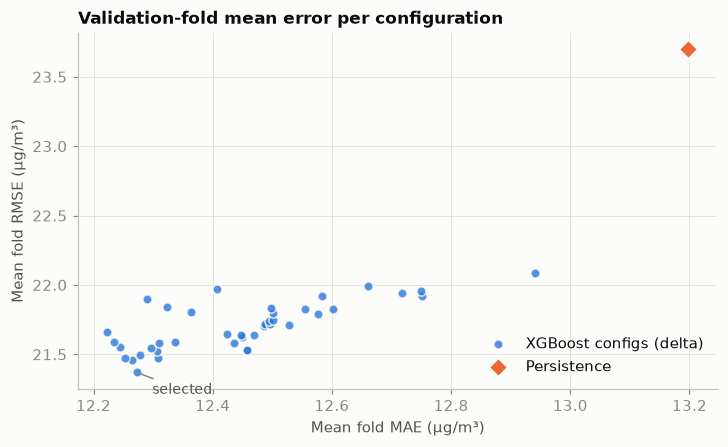

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.scatter(search['MAE'], search['RMSE'], s=36, color=ps.SERIES[0], alpha=0.8, edgecolor=ps.SURFACE, linewidth=1, label='XGBoost configs (delta)')
ax.scatter([PERS['MAE']], [PERS['RMSE']], s=80, marker='D', color=ps.SERIES[1], edgecolor=ps.SURFACE, linewidth=1.5, label='Persistence')
best = search.iloc[0]
ax.annotate('selected', (best['MAE'], best['RMSE']), xytext=(10, -14), textcoords='offset points', fontsize=9, color=ps.INK_2,
            arrowprops=dict(arrowstyle='-', color=ps.MUTED))
ax.set(title='Validation-fold mean error per configuration', xlabel='Mean fold MAE (µg/m³)', ylabel='Mean fold RMSE (µg/m³)')
ax.legend(loc='lower right')
ps.save(fig, 'xgb_01_search'); plt.show()

## 3. Is the tuning gain larger than run-to-run noise?
With `subsample`/`colsample` < 1 the result depends on the random seed. The selected and initial configurations are re-run with 5 seeds; a tuning gain smaller than the seed spread would not be meaningful.

In [6]:
SELECTED = {k: best[k] for k in SPACE}
SELECTED = {k: (int(v) if k in ('max_depth', 'n_estimators', 'min_child_weight', 'reg_lambda') else float(v)) for k, v in SELECTED.items()}
seed_rows = []
for name, c in [('initial', INITIAL | {'reg_lambda': 1}), ('selected', SELECTED)]:
    for sd in range(5):
        r, _ = E.backtest(lambda: XGBForecaster('delta', **c, random_state=sd), X, y, mask, FOLDS)
        seed_rows.append({'config': name, 'seed': sd, **r[['MAE', 'RMSE']].mean().to_dict()})
seeds = pd.DataFrame(seed_rows)
seeds.groupby('config')[['MAE', 'RMSE']].agg(['mean', 'std', 'min', 'max']).round(3)

MAE                           RMSE                       
            mean    std     min     max    mean    std     min     max
config                                                                
initial   12.525  0.039  12.496  12.592  21.740  0.034  21.708  21.797
selected  12.308  0.025  12.273  12.342  21.414  0.037  21.369  21.456

## 4. Selected model vs persistence (validation folds)

In [7]:
print('selected config:', SELECTED)
xgb_folds, xgb_pred = E.backtest(lambda: XGBForecaster('delta', **SELECTED), X, y, mask, FOLDS)
cmp = xgb_folds[['fold', 'test_start', 'test_end', 'n_train', 'n']].copy()
for mtr in ['MAE', 'RMSE', 'R2']:
    cmp[f'{mtr} pers'] = pers_folds[mtr].values; cmp[f'{mtr} xgb'] = xgb_folds[mtr].values
for mtr in ['MAE', 'RMSE']:
    cmp[f'{mtr} change %'] = 100 * (cmp[f'{mtr} xgb'] - cmp[f'{mtr} pers']) / cmp[f'{mtr} pers']
cmp.round(3)

selected config: {'max_depth': 6, 'learning_rate': 0.02, 'n_estimators': 800, 'min_child_weight': 10, 'subsample': 0.85, 'colsample_bytree': 0.6, 'reg_lambda': 5}


,fold,test_start,test_end,n_train,n,MAE pers,MAE xgb,RMSE pers,RMSE xgb,R2 pers,R2 xgb,MAE change %,RMSE change %
0,1,2013-01-01,2013-03-31,24274,2127,17.906,17.154,35.762,32.880,0.933,0.943,-4.201,-8.057
1,2,2013-04-01,2013-06-30,26412,2129,11.663,10.999,19.517,18.033,0.908,0.921,-5.695,-7.607
2,3,2013-07-01,2013-09-30,28564,2161,9.172,8.398,15.296,13.276,0.914,0.935,-8.432,-13.205
3,4,2013-10-01,2013-12-31,30744,2146,14.052,12.541,24.225,21.288,0.940,0.954,-10.750,-12.126


In [8]:
vm = mask & (split == 'val')
assert xgb_pred.index.equals(y[vm].index)
pooled = pd.DataFrame([{'model': 'persistence', **E.metrics(y[vm], persist[vm])},
                       {'model': 'xgboost (selected, delta)', **E.metrics(y[vm], xgb_pred)}]).set_index('model')
pooled.round(3)

,n,MAE,RMSE,R2
model,,,,
persistence,8563,13.184,24.870,0.936
"xgboost (selected, delta)",8563,12.258,22.526,0.947


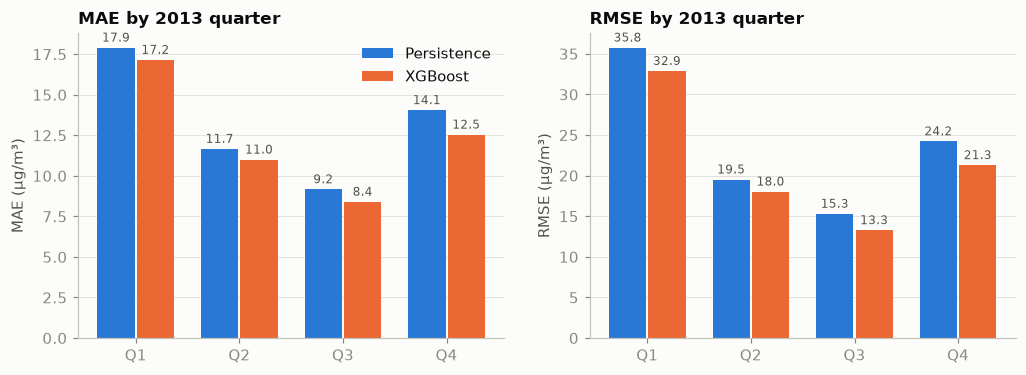

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(4); w = 0.38
for ax, mtr in zip(axes, ['MAE', 'RMSE']):
    for i, (lab, col) in enumerate([('Persistence', f'{mtr} pers'), ('XGBoost', f'{mtr} xgb')]):
        b = ax.bar(x + (i - 0.5) * w, cmp[col], width=w - 0.02, color=ps.SERIES[i], label=lab)
        ax.bar_label(b, fmt='%.1f', fontsize=8, color=ps.INK_2, padding=2)
    ax.set_xticks(x, ['Q1', 'Q2', 'Q3', 'Q4']); ax.grid(axis='x', visible=False)
    ax.set(title=f'{mtr} by 2013 quarter', ylabel=f'{mtr} (µg/m³)')
axes[0].legend(loc='upper right')
ps.save(fig, 'xgb_02_vs_persistence'); plt.show()

In [10]:
err_p, err_x = (persist[vm] - y[vm]), (xgb_pred - y[vm])
lvl = pd.cut(y[vm], [0, 35, 75, 150, 250, 1000], labels=['0–35', '35–75', '75–150', '150–250', '>250'], include_lowest=True)
pd.DataFrame({'hours': err_p.groupby(lvl, observed=True).size(),
              'RMSE pers': err_p.pow(2).groupby(lvl, observed=True).mean().pow(.5),
              'RMSE xgb': err_x.pow(2).groupby(lvl, observed=True).mean().pow(.5),
              'MAE pers': err_p.abs().groupby(lvl, observed=True).mean(),
              'MAE xgb': err_x.abs().groupby(lvl, observed=True).mean()}).round(1)

,hours,RMSE pers,RMSE xgb,MAE pers,MAE xgb
pm25_t+1,,,,,
0–35,2355,14.1,11.8,6.0,5.8
35–75,2107,19.9,16.0,11.2,9.8
75–150,2227,22.4,19.8,14.2,12.5
150–250,1145,33.9,29.4,19.8,17.9
>250,729,46.3,47.1,28.7,30.5


## 5. Feature importance
Model trained on the **training split only** (targets 2010–2012) with the selected configuration.
- **Gain:** average loss reduction from splits on a feature. Computed on training data; biased towards high-cardinality features.
- **Permutation (validation 2013):** increase in RMSE when one feature column is shuffled. Only the model input is permuted; the pm(t) added back by the delta formulation is kept intact, so this measures importance for predicting the **change**.

*Caveats:* correlated features (e.g. lags and rolling means) share or mask each other's importance; importance is association within this model, not causation.

In [11]:
trm = (split == 'train') & y.notna()
fm = XGBForecaster('delta', **SELECTED).fit(X[trm], y[trm])
gain = pd.Series(fm.model.get_booster().get_score(importance_type='gain')).reindex(X.columns).fillna(0)
Xv, yv = X[vm], y[vm]
base_rmse = E.metrics(yv, fm.predict(Xv))['RMSE']
prng = np.random.default_rng(SEED); perm = {}
for c in X.columns:
    inc = []
    for _ in range(5):
        Xp = Xv.copy(); Xp[c] = prng.permutation(Xp[c].values)
        p = fm.model.predict(Xp) + Xv['pm_lag0'].to_numpy()   # keep the add-back term intact
        inc.append(E.metrics(yv, p)['RMSE'] - base_rmse)
    perm[c] = (np.mean(inc), np.std(inc))
imp = pd.DataFrame({'gain': gain, 'gain %': 100 * gain / gain.sum(),
                    'perm ΔRMSE': {c: v[0] for c, v in perm.items()}, 'perm ΔRMSE std': {c: v[1] for c, v in perm.items()}})
imp = imp.sort_values('perm ΔRMSE', ascending=False)
print(f'validation RMSE of this train-only model: {base_rmse:.3f}')
imp.round(3).head(15)

validation RMSE of this train-only model: 22.537


,gain,gain %,perm ΔRMSE,perm ΔRMSE std
pm_lag0,7778.426,3.176,2.296,0.094
wind_speed,16027.329,6.545,2.229,0.194
dewp_diff3,8653.186,3.534,0.682,0.096
pm_lag1,8450.049,3.451,0.454,0.044
pm_mean3,8895.428,3.633,0.452,0.043
pm_diff1,10677.692,4.360,0.450,0.016
hour_sin,6493.042,2.652,0.323,0.059
dewp,7132.352,2.913,0.283,0.031
dewp_spread,7491.098,3.059,0.279,0.078
wind_NW,15365.023,6.275,0.169,0.032


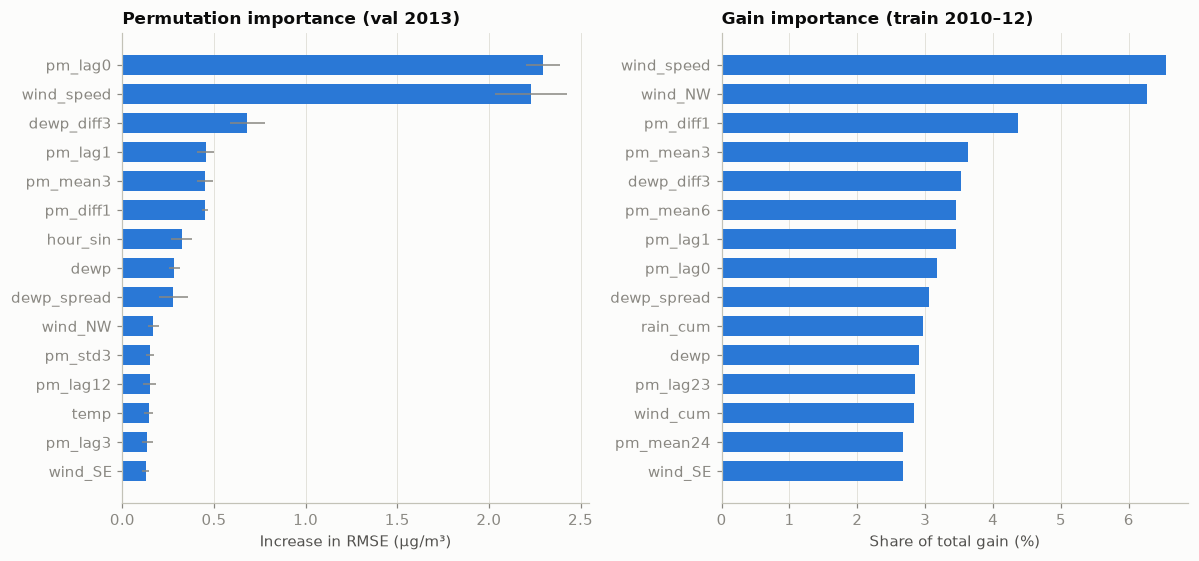

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
top = imp.head(15).iloc[::-1]
axes[0].barh(top.index, top['perm ΔRMSE'], xerr=top['perm ΔRMSE std'], color=ps.SERIES[0], height=0.7, error_kw=dict(ecolor=ps.MUTED, lw=1))
axes[0].set(title='Permutation importance (val 2013)', xlabel='Increase in RMSE (µg/m³)')
tg = imp.sort_values('gain %', ascending=False).head(15).iloc[::-1]
axes[1].barh(tg.index, tg['gain %'], color=ps.SERIES[0], height=0.7)
axes[1].set(title='Gain importance (train 2010–12)', xlabel='Share of total gain (%)')
for ax in axes: ax.grid(axis='y', visible=False)
fig.tight_layout(); ps.save(fig, 'xgb_03_importance'); plt.show()

In [13]:
print('features with ~zero permutation importance (|ΔRMSE| < 0.01):')
print(imp.index[imp['perm ΔRMSE'].abs() < 0.01].tolist())

features with ~zero permutation importance (|ΔRMSE| < 0.01):
['wind_cv', 'wind_NE', 'pm_std24', 'pm_hours_since_obs', 'snow_cum']


## 6. Save configuration, metrics and predictions

In [14]:
M = E.RESULTS_DIR / 'metrics'
cfg = {'formulation': 'delta', 'objective': 'reg:squarederror', 'tree_method': 'hist', 'random_state': SEED,
       **SELECTED, 'selection': 'lowest mean RMSE over 4 expanding-window folds (2013 quarters)',
       'xgboost_version': __import__('xgboost').__version__}
(M / 'xgb_selected_config.json').write_text(json.dumps(cfg, indent=2))
forms.to_csv(M / 'xgb_formulations.csv'); search.to_csv(M / 'xgb_search.csv', index=False)
seeds.to_csv(M / 'xgb_seed_check.csv', index=False); cmp.to_csv(M / 'xgb_val_folds.csv', index=False)
imp.to_csv(M / 'xgb_feature_importance.csv', index_label='feature')
pd.DataFrame({'target_time': xgb_pred.index + pd.Timedelta(hours=1), 'y_true': y[vm], 'persistence': persist[vm], 'xgboost': xgb_pred}) \
  .to_csv(E.RESULTS_DIR / 'predictions' / 'xgb_val_folds.csv', index_label='issue_time')
print(json.dumps(cfg, indent=2))

{
  "formulation": "delta",
  "objective": "reg:squarederror",
  "tree_method": "hist",
  "random_state": 0,
  "max_depth": 6,
  "learning_rate": 0.02,
  "n_estimators": 800,
  "min_child_weight": 10,
  "subsample": 0.85,
  "colsample_bytree": 0.6,
  "reg_lambda": 5,
  "selection": "lowest mean RMSE over 4 expanding-window folds (2013 quarters)",
  "xgboost_version": "3.2.0"
}


## 7. Findings (validation 2013 only; test year untouched)
1. **Target formulation mattered more than tuning.** With the same settings, predicting the level reached RMSE 23.79 (no better than persistence at 23.70); predicting the change reached 21.80.
2. **Tuning helped a little, but more than seed noise.** The selected configuration lowers mean fold RMSE from 21.74 to 21.41 (5-seed std ≈ 0.04). Many configurations score within about 0.1 of each other, so the exact choice is not critical. Two sampled configurations were duplicates.
3. **XGBoost beats persistence in every quarter:** MAE −4% to −11%, RMSE −8% to −13%. Pooled over 2013: MAE 12.26 vs 13.18, RMSE 22.53 vs 24.87, R² 0.947 vs 0.936.
4. **No gain on the most extreme hours:** for true PM2.5 > 250 µg/m³ (729 h), XGBoost is slightly worse than persistence (RMSE 47.1 vs 46.3, MAE 30.5 vs 28.7). The gains come from low and moderate levels. Stage 08 will examine this.
5. **Importance:** pm(t) and the decoded hourly `wind_speed` dominate permutation importance (≈ 2.3 µg/m³ RMSE increase each), followed by the 3-hour dew-point change. This supports decoding `Iws`. Gain ranks `rain_cum` highly although its permutation importance is small, an example of gain bias.
6. **Near-zero permutation importance:** `wind_cv`, `wind_NE`, `pm_std24`, `pm_hours_since_obs`, `snow_cum`. They are kept: removing them is not expected to change results materially, and pruning would be another selection step on validation data.